# 07 · Short-history risk transfer

**Question:** given a currently quoted copper contract and only a few permitted
own price changes, can other contracts supply useful next-session risk information?

This compares learned maturity-dependent return factors with transport-SPDE source
estimation, both with the same residual-transfer adapter. It is an exploratory
information-restriction experiment on inspected daily settlements, not a genuine
new-listing experiment. The current settlement remains visible. Historical target
rows are removed before reconstruction, loading fitting, scaling and estimation.

[Protocol](../docs/short_history.md) · [Generated report](../experiments/results/short-history/report.md)
· [Project findings](00_project_findings.ipynb)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_short_history import load_short_history_evidence

evidence = load_short_history_evidence(Path("../experiments/results/short-history"))
config = evidence["protocol"]["config"]
print("Numerical source:", evidence["manifest"]["code_revision"])
print("Clean numerical source:", not evidence["manifest"]["source_dirty"])
print("Target:", evidence["protocol"]["forecast_target"])
print("Primary comparison:", evidence["protocol"]["primary_comparison"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
METHODS = ("dfm_joint", "spde_joint", "pooled_shrink", "direct")
LABELS = {
    "dfm_joint": "Learned factors + residual",
    "spde_joint": "Transport + residual",
    "pooled_shrink": "Maturity pool + short history",
    "direct": "Same-contract direct",
    "spde_uniform": "Original uniform source C",
    "spde_ewma": "EWMA source C",
    "dfm_uniform_joint": "Uniform learned factors + residual",
    "dfm_factor": "Learned factors only",
    "spde_joint_no_nugget": "Transport, no diagonal correction",
    "dfm_joint_no_nugget": "Learned factors, no diagonal correction",
    "outright": "Outright",
    "spread": "Target / nearest spread",
    "butterfly": "Butterfly",
    "hedge": "Bounded hedge",
    "all": "All available",
}
COLORS = {
    "dfm_joint": "#1f77b4",
    "spde_joint": "#d95f02",
    "pooled_shrink": "#666666",
    "direct": "#228833",
}


def display(value):
    if value is None:
        return "Unavailable"
    if isinstance(value, float):
        return f"{value:,.4g}"
    if isinstance(value, (list, tuple)):
        return "[" + ", ".join(display(x) for x in value) + "]"
    return LABELS.get(str(value), str(value))


def table(rows, columns):
    return "\n".join(
        [
            "| " + " | ".join(label for _, label in columns) + " |",
            "| " + " | ".join("---" for _ in columns) + " |",
            *(
                "| " + " | ".join(display(row.get(key)) for key, _ in columns) + " |"
                for row in rows
            ),
        ]
    )


def phase(evidence):
    names = {r["phase"] for r in evidence["summary"]["rows"]}
    if "evaluation" in names:
        return "evaluation"
    if "test" in names:
        return "test"
    raise ValueError("no evaluation rows in evidence; validation is not a substitute")


def budgets(evidence):
    return [
        "all" if h is None else str(h) for h in evidence["protocol"]["config"]["history_budgets"]
    ]


def primary(evidence, *, tenor="all"):
    config = evidence["protocol"]["config"]
    return [
        r
        for r in evidence["summary"]["rows"]
        if r["phase"] == phase(evidence)
        and r["half_life"] == config["half_life"]
        and r["tenor"] == str(tenor)
    ]


def paired(evidence, *, exposure, tenor="all", half_life=None):
    config = evidence["protocol"]["config"]
    half_life = config["half_life"] if half_life is None else half_life
    rows = [
        r
        for r in evidence["paired"]["rows"]
        if r["phase"] == phase(evidence)
        and r["half_life"] == half_life
        and r["tenor"] == str(tenor)
        and r["method"] == "dfm_joint"
        and r["reference"] == "spde_joint"
        and r["exposure"] == exposure
    ]
    return sorted(rows, key=lambda row: budgets(evidence).index(row["budget"]))


def interval(row, block):
    values = [x for x in row["bootstrap"] if x["block_origins"] == block]
    if not values:
        return None
    return values[0]["percentile_95"]


def plot_scores(evidence):
    """Paired QLIKE differences by history budget and target maturity."""
    config, history = evidence["protocol"]["config"], budgets(evidence)
    tenors = config["target_tenors_days"]
    fig, axes = plt.subplots(1, len(tenors), figsize=(12.3, 4.0), squeeze=False)
    colors = ("#1f77b4", "#d95f02", "#555555")
    for ax, tenor in zip(axes[0], tenors, strict=True):
        ax.axhline(0, color="0.6", lw=1)
        for j, (exposure, color) in enumerate(
            zip(("outright", "spread", "butterfly"), colors, strict=True)
        ):
            rows = paired(evidence, exposure=exposure, tenor=tenor)
            offset = (j - 1) * 0.17
            for k, row in enumerate(rows):
                bounds = interval(row, config["bootstrap_block"])
                x, mean = history.index(row["budget"]) + offset, row["difference"]
                if bounds is not None:
                    ax.plot([x, x], bounds, color=color, lw=1.3)
                ax.plot(x, mean, "o", color=color, ms=4, label=LABELS[exposure] if k == 0 else None)
        ax.set(
            title=f"Target near {tenor} days",
            xticks=range(len(history)),
            xticklabels=["All" if h == "all" else h for h in history],
            xlabel="Permitted own changes",
        )
        ax.grid(axis="y", alpha=0.18)
    axes[0, 0].set_ylabel("QLIKE: learned factors − transport\n(shared residual adapter)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
    fig.suptitle("Matched risk forecasts: negative differences favor learned factors", fontsize=12)
    fig.tight_layout(rect=(0, 0.10, 1, 0.94))
    return fig


def plot_calibration(evidence):
    """Ratios of origin-averaged forecast and realized second moments."""
    history = budgets(evidence)
    rows = primary(evidence)
    fig, axes = plt.subplots(1, 3, figsize=(12.3, 3.8))
    for ax, exposure in zip(axes, ("outright", "spread", "butterfly"), strict=True):
        ax.axhline(1, color="0.5", lw=1)
        for method in METHODS:
            lookup = {r["budget"]: r for r in rows if r["method"] == method}
            values = [
                lookup[h]["metrics"].get(exposure, {}).get("calibration_ratio")
                if h in lookup
                else None
                for h in history
            ]
            values = [np.nan if value is None or value <= 0 else value for value in values]
            ax.plot(
                range(len(history)), values, "o-", color=COLORS[method], ms=4, label=LABELS[method]
            )
        ax.set(
            title=LABELS[exposure],
            xticks=range(len(history)),
            xticklabels=["All" if h == "all" else h for h in history],
            xlabel="Permitted own changes",
            yscale="log",
        )
        ax.grid(axis="y", alpha=0.18)
    axes[0].set_ylabel("Forecast / realized second moment\n(log scale; one is calibrated)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Risk calibration across history budgets; all target maturities", fontsize=12)
    fig.tight_layout(rect=(0, 0.16, 1, 0.94))
    return fig


def plot_hedges(evidence):
    """Paired squared hedge P&L, with half-life and block sensitivities."""
    config, history = evidence["protocol"]["config"], budgets(evidence)
    half_lives = [config["half_life"], *config["sensitivity_half_lives"]]
    blocks = list(
        dict.fromkeys([config["bootstrap_block"], *config["bootstrap_sensitivity_blocks"]])
    )
    fig, axes = plt.subplots(
        1, len(half_lives), figsize=(4.1 * len(half_lives), 4.1), squeeze=False
    )
    colors = plt.cm.Greys(np.linspace(0.85, 0.35, len(blocks)))
    for ax, half_life in zip(axes[0], half_lives, strict=True):
        ax.axhline(0, color="0.6", lw=1)
        rows = paired(evidence, exposure="hedge", half_life=half_life)
        for j, block in enumerate(blocks):
            for k, row in enumerate(rows):
                bounds = interval(row, block)
                x = history.index(row["budget"]) + (j - (len(blocks) - 1) / 2) * 0.13
                if bounds is not None:
                    ax.plot([x, x], np.asarray(bounds) / 1000, color=colors[j], lw=1.3)
                ax.plot(
                    x,
                    row["difference"] / 1000,
                    "o",
                    color=colors[j],
                    ms=3.5,
                    label=f"Block {block} origins" if k == 0 else None,
                )
        ax.set(
            title=f"Half-life {half_life:g} sessions",
            xticks=range(len(history)),
            xticklabels=["All" if h == "all" else h for h in history],
            xlabel="Permitted own changes",
        )
        ax.grid(axis="y", alpha=0.18)
    axes[0, 0].set_ylabel("Squared hedge P&L: learned − transport\n(thousand CNY²)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(4, len(blocks)), frameon=False)
    fig.suptitle("Bounded hedge outcomes: fixed sensitivities, no selected winner", fontsize=12)
    fig.tight_layout(rect=(0, 0.10, 1, 0.94))
    return fig


def detail_tables(evidence):
    """Human-scale ablation, component and numerical tables from aggregates."""
    rows, ablations, components, numerical = primary(evidence), [], [], []
    model_names = (
        "spde_uniform",
        "spde_ewma",
        "spde_joint",
        "dfm_joint",
        "dfm_uniform_joint",
        "dfm_factor",
        "spde_joint_no_nugget",
        "dfm_joint_no_nugget",
    )
    for budget in budgets(evidence):
        for method in model_names:
            matches = [r for r in rows if r["budget"] == budget and r["method"] == method]
            if not matches:
                continue
            row = matches[0]
            item = {"budget": budget, "method": method}
            for exposure in ("outright", "spread", "butterfly"):
                item[exposure] = row["metrics"][exposure].get("qlike")
            value = row["metrics"]["joint"].get("quadratic")
            item["joint"] = None if value is None else value / 1e12
            item["rms"] = row["metrics"]["hedge"].get("realized_rms_cny")
            ablations.append(item)
        for method in ("dfm_joint", "spde_joint"):
            matches = [r for r in rows if r["budget"] == budget and r["method"] == method]
            if not matches:
                continue
            for exposure in ("outright", "spread", "butterfly"):
                values = matches[0]["metrics"][exposure]
                total = values.get("forecast")
                item = {"budget": budget, "method": method, "exposure": exposure, "total": total}
                for name, key in (
                    ("factor", "factor"),
                    ("cross", "cross_correction"),
                    ("residual", "correlated_residual"),
                    ("diagonal", "diagonal_prediction_error"),
                ):
                    value = values.get("components", {}).get(key)
                    item[name] = (
                        None
                        if total is None or total <= 0 or value is None
                        else 100 * value / total
                    )
                components.append(item)
    for row in evidence["diagnostics"]["methods"]:
        if row["method"] not in model_names:
            continue
        values = row["numeric_min_median_max"]

        def pick(name, position=2):
            triple = values.get(name)
            return triple[position] if triple else None

        numerical.append(
            {
                "method": row["method"],
                "covariance_bound": pick("source_relative_covariance_error_bound"),
                "objective_gap": pick("source_objective_gap_bound"),
                "iterations": pick("source_iterations"),
                "effective": "N/A"
                if row["method"] == "spde_uniform"
                else pick("effective_interval_count", 1),
                "curve_condition": pick("curve_condition_max"),
                "residual_condition": pick("residual_feature_condition_max"),
                "eigen_gap": pick("third_fourth_relative_eigengap", 0),
                "support": pick("relative_support_residual"),
                "schur": pick("schur_psd_roundoff_correction"),
                "psd": pick("forecast_psd_roundoff_correction"),
                "component": pick("component_sum_relative_residual"),
                "remaining": values.get("remaining_residual_signed_pair_product_ratio"),
            }
        )
    return ablations, components, numerical


assert evidence["paired"]["joint_resampling"]
assert config["history_budgets"] == [0, 5, 20, None]

Numerical source: 95bd9ba0adac335146fcc54b7e2e36b7ae1b0aa0
Clean numerical source: True
Target: uncentered same-contract price-change second moments
Primary comparison: dfm_joint versus spde_joint: complete policies, not causal transport effect


## What this experiment finds

**The proposed learned-factor policy does not improve short-history spread-risk forecasting in this study.** The transport model is more stable than this DFM implementation, while a simple maturity-pooling baseline remains competitive. These are complete-policy comparisons on inspected data, not a universal result about SPDEs or factor models.

At zero own history, the DFM spread forecast is **19.26 times** realized second moment, reaching **57.10 times** for the near-90-day target. The diagonal leave-one-donor-out correction contributes **CNY² 9.074 million** of the **CNY² 9.254 million** forecast (98.1%). This flags a failure of the present predictive-error transfer policy, not evidence of high true latent noise.

Primary DFM-minus-transport spread QLIKE differences (positive favors transport):

- Own history 0: **+0.712**, block range [0.525, 0.891].
- Own history 5: **+0.612**, block range [0.426, 0.784].
- Own history 20: **+0.510**, block range [0.314, 0.678].
- Own history All available: **+0.118**, block range [0.057, 0.182].

The direction persists across all prespecified half-lives and block lengths. These dependent sensitivity checks do not constitute independent confirmation.

**Removing the diagonal correction is not a complete repair.** At zero own history, the DFM without it forecasts only 0.374 times realized spread second moment and has QLIKE 15.860; factor-only QLIKE is 26.407, versus 14.816 with the full correction. The current factor/residual representation underpredicts without the correction and overpredicts with it.

**The simple pooled baseline must remain central.** At zero own history, transport-minus-pool spread QLIKE is −0.068, block range [−0.204, 0.037], which does not resolve an advantage. At five own changes it is +0.130 [0.006, 0.280], favoring pooling. Pooled hedge RMS is lower at every history budget; this is settlement-risk evidence without execution costs.

The next diagnostic should examine learned-loading stability, leave-one-donor-out leverage and how predictive errors transfer across maturities. Do not retune this inspected sample or add complexity before explaining this failure. A revised rule requires a frozen protocol and an uninspected confirmation period.

## Information and financial targets

The 2022 initial period, 2023 development validation and inspected 2024–2025
evaluation are retained. Origins occur every five sessions, with three targets
near 90, 180 and 270 days. Own-history budgets are 0, 5, 20 and all available
changes in a 252-interval window. Missing observations never create bridged returns.

Both methods forecast the uncentered price-change second moment
$$B_t=\mathbb E_t[\Delta p_{t+1}\Delta p_{t+1}^{\top}].$$
For a five-tonne contract position a, the P&L second moment is
$$25a^{\top}B_ta.$$
A variance interpretation requires negligible conditional means.
The target/nearest spread and original near/middle/far butterfly preserve actual
contract identities. The principal comparison is between complete policies,
not a causal estimate of the benefit of transport alone.

In [2]:
rows = primary(evidence)
availability = [
    {
        "budget": r["budget"],
        "policy": LABELS[r["method"]],
        "scored": f"{r['scored']}/{r['episodes']}",
        "origins": r["origins"],
    }
    for r in rows
    if r["method"] in METHODS
]
print(
    table(
        availability,
        [
            ("budget", "Own history"),
            ("policy", "Policy"),
            ("scored", "Scored / attempted"),
            ("origins", "Origins"),
        ],
    )
)
assert all(r["scored"] <= r["available"] <= r["episodes"] for r in rows)

| Own history | Policy | Scored / attempted | Origins |
| --- | --- | --- | --- |
| 0 | Learned factors + residual | 291/291 | 97 |
| 0 | Same-contract direct | 0/291 | 0 |
| 0 | Maturity pool + short history | 291/291 | 97 |
| 0 | Transport + residual | 291/291 | 97 |
| 20 | Learned factors + residual | 291/291 | 97 |
| 20 | Same-contract direct | 291/291 | 97 |
| 20 | Maturity pool + short history | 291/291 | 97 |
| 20 | Transport + residual | 291/291 | 97 |
| 5 | Learned factors + residual | 291/291 | 97 |
| 5 | Same-contract direct | 0/291 | 0 |
| 5 | Maturity pool + short history | 291/291 | 97 |
| 5 | Transport + residual | 291/291 | 97 |
| All available | Learned factors + residual | 291/291 | 97 |
| All available | Same-contract direct | 291/291 | 97 |
| All available | Maturity pool + short history | 291/291 | 97 |
| All available | Transport + residual | 291/291 | 97 |


## Paired forecast scores by history and maturity

Negative QLIKE differences favor learned factors. Each difference uses the same
future observation and permitted history. Vertical lines show descriptive 95%
calendar-origin block-bootstrap percentile ranges. Targets are averaged within
origin before pooling; contracts and history budgets are not independent draws.
The primary block has four scheduled origins, approximately 20 trading sessions.

| Own history | Target | Learned − transport | 95% block range | Paired origins |
| --- | --- | --- | --- | --- |
| 0 | Outright | -0.1409 | [-0.4165, 0.06223] | 97 |
| 5 | Outright | -0.1349 | [-0.3695, 0.05022] | 97 |
| 20 | Outright | -0.08851 | [-0.2267, 0.03338] | 97 |
| All available | Outright | -0.01642 | [-0.06032, 0.009687] | 97 |
| 0 | Target / nearest spread | 0.7123 | [0.5249, 0.8905] | 97 |
| 5 | Target / nearest spread | 0.6116 | [0.4262, 0.7838] | 97 |
| 20 | Target / nearest spread | 0.5102 | [0.3143, 0.678] | 97 |
| All available | Target / nearest spread | 0.1176 | [0.05661, 0.182] | 97 |
| 0 | Butterfly | 0.436 | [-0.1779, 0.9191] | 97 |
| 5 | Butterfly | 0.4038 | [-0.189, 0.8647] | 97 |
| 20 | Butterfly | 0.3398 | [-0.2425, 0.7889] | 97 |
| All available | Butterfly | 0.1205 | [0.063, 0.1822] | 97 |


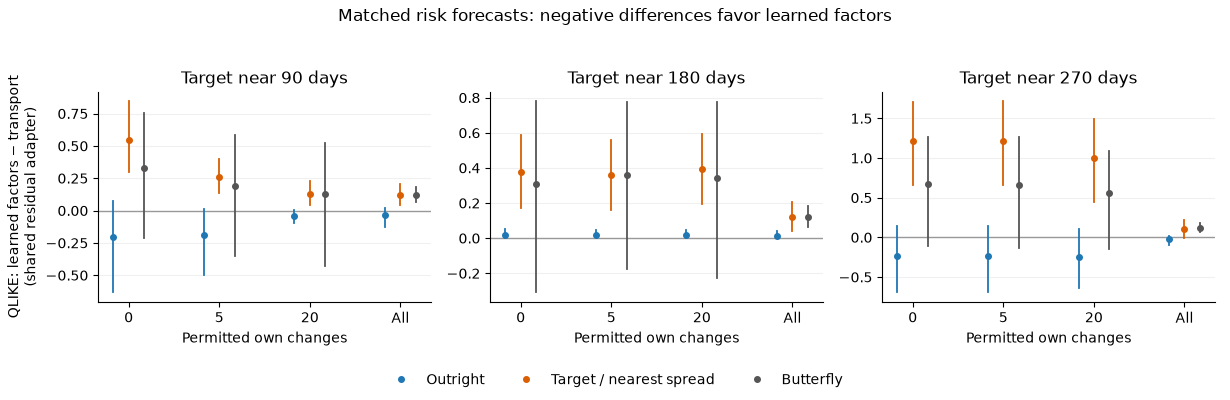

In [3]:
plot_scores(evidence)
plt.show()
comparison_rows = []
for exposure in ("outright", "spread", "butterfly"):
    for row in paired(evidence, exposure=exposure):
        comparison_rows.append(
            {
                "budget": row["budget"],
                "exposure": exposure,
                "difference": row["difference"],
                "range": interval(row, config["bootstrap_block"]),
                "origins": row["paired_origins"],
            }
        )
print(
    table(
        comparison_rows,
        [
            ("budget", "Own history"),
            ("exposure", "Target"),
            ("difference", "Learned − transport"),
            ("range", "95% block range"),
            ("origins", "Paired origins"),
        ],
    )
)

## Calibration and residual contributions

The ratio below is forecast divided by realized second moment: values below one
indicate underprediction. Aggregate calibration does not establish conditional
calibration. The joint moment retains factor/residual cross terms. Four correlated
residual maturity features and a diagonal remainder remain a modeling restriction.
The diagonal correction is fitted from leave-one-donor-out predictive errors,
which can contain estimation error; it is not identified latent market noise.

Component shares as percentages of forecast second moment; signed cross terms are retained.
| Own history | Policy | Risk | Factor % | Signed cross % | Correlated residual % | Diagonal % | Forecast CNY² |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | Learned factors + residual | Outright | 48.23 | 0.04599 | 0.117 | 51.61 | 1.671e+07 |
| 0 | Learned factors + residual | Target / nearest spread | 1.476 | 0.02722 | 0.4407 | 98.06 | 9.254e+06 |
| 0 | Learned factors + residual | Butterfly | 2.124 | 0.1562 | 0.9546 | 96.77 | 1.139e+07 |
| 0 | Transport + residual | Outright | 96.83 | 0.07614 | 0.1732 | 2.92 | 8.279e+06 |
| 0 | Transport + residual | Target / nearest spread | 15.29 | 1.099 | 5.326 | 78.28 | 5.865e+05 |
| 0 | Transport + residual | Butterfly | 7.77 | -2.173 | 6.135 | 88.27 | 1.558e+06 |
| 5 | Learned factors + residual | Outright | 70.59 | 0.05547 | 0.1678 | 29.19 | 1.141e+07 |
| 5 | Learned factors + residual | Target / nearest spread | 3.304 | 0.06429 | 1.027 | 95

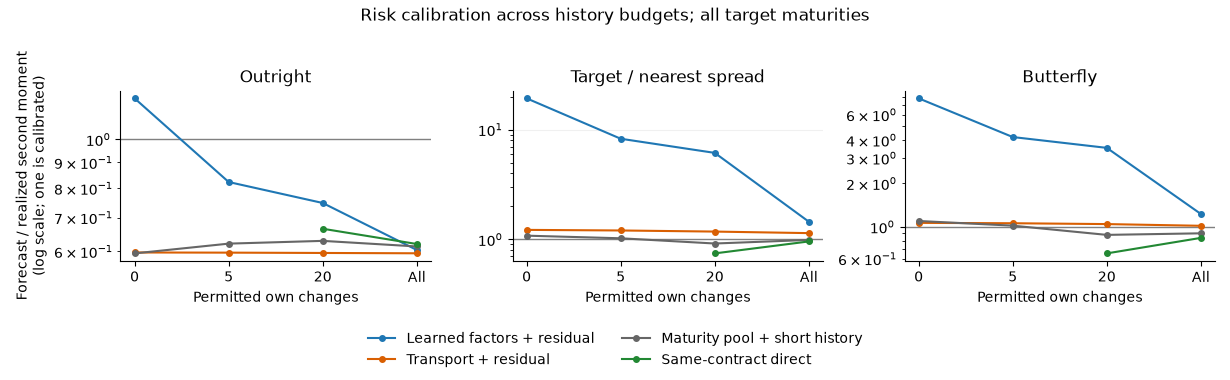

In [4]:
plot_calibration(evidence)
plt.show()
ablations, components, numerical = detail_tables(evidence)
print("Component shares as percentages of forecast second moment; signed cross terms are retained.")
print(
    table(
        components,
        [
            ("budget", "Own history"),
            ("method", "Policy"),
            ("exposure", "Risk"),
            ("factor", "Factor %"),
            ("cross", "Signed cross %"),
            ("residual", "Correlated residual %"),
            ("diagonal", "Diagonal %"),
            ("total", "Forecast CNY²"),
        ],
    )
)
assert all(
    abs(sum(row[key] for key in ("factor", "cross", "residual", "diagonal")) - 100) < 1e-5
    for row in components
    if all(row[key] is not None for key in ("factor", "cross", "residual", "diagonal"))
)

## Bounded hedges and prespecified sensitivities

One target contract is hedged with two positions bounded to [−2,2]. Negative
paired mean squared-P&L differences favor learned factors. Values are in
thousand CNY², not differences between RMS values. Half-lives 21, 63 and 126
sessions and block lengths 1, 2, 4 and 8 origins are fixed sensitivities.
No winner is selected from evaluation performance. Execution, rolls, costs,
margin and capacity are absent.

| Own history | Policy | Hedge RMS CNY | Origins |
| --- | --- | --- | --- |
| 0 | Learned factors + residual | 669.9 | 97 |
| 0 | Same-contract direct | Unavailable | 0 |
| 0 | Maturity pool + short history | 621.5 | 97 |
| 0 | Transport + residual | 647.2 | 97 |
| 20 | Learned factors + residual | 674.8 | 97 |
| 20 | Same-contract direct | 629.6 | 97 |
| 20 | Maturity pool + short history | 618.4 | 97 |
| 20 | Transport + residual | 649.3 | 97 |
| 5 | Learned factors + residual | 675 | 97 |
| 5 | Same-contract direct | Unavailable | 0 |
| 5 | Maturity pool + short history | 603.6 | 97 |
| 5 | Transport + residual | 649.1 | 97 |
| All available | Learned factors + residual | 655.7 | 97 |
| All available | Same-contract direct | 646.7 | 97 |
| All available | Maturity pool + short history | 638.9 | 97 |
| All available | Transport + residual | 648.5 | 97 |


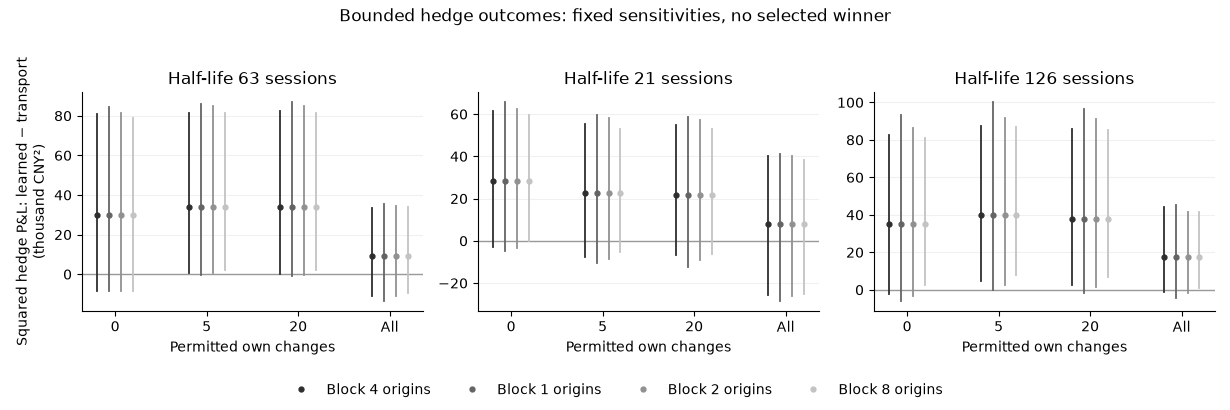

In [5]:
plot_hedges(evidence)
plt.show()
hedges = [
    {
        "budget": row["budget"],
        "method": row["method"],
        "rms": row["metrics"]["hedge"].get("realized_rms_cny"),
        "origins": row["origins"],
    }
    for row in rows
    if row["method"] in METHODS
]
print(
    table(
        hedges,
        [
            ("budget", "Own history"),
            ("method", "Policy"),
            ("rms", "Hedge RMS CNY"),
            ("origins", "Origins"),
        ],
    )
)

## Full policy and ablation audit

All eight model policies remain visible, including original uniform source C,
recency weighting, factor-only and no-diagonal-correction ablations. Joint
quadratic values are scaled by 10¹² CNY⁴. A negative quadratic score is valid:
the score omits a forecast-independent term. These are descriptive levels;
use matched common-outcome differences for comparisons.

In [6]:
print(
    table(
        ablations,
        [
            ("budget", "Own history"),
            ("method", "Policy"),
            ("outright", "Outright QLIKE"),
            ("spread", "Spread QLIKE"),
            ("butterfly", "Butterfly QLIKE"),
            ("joint", "Joint quadratic / 10¹² CNY⁴"),
            ("rms", "Hedge RMS CNY"),
        ],
    )
)
assert len({row["method"] for row in ablations}) == 8

| Own history | Policy | Outright QLIKE | Spread QLIKE | Butterfly QLIKE | Joint quadratic / 10¹² CNY⁴ | Hedge RMS CNY |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | Original uniform source C | 17.96 | 17.69 | 24.67 | -1,001 | 778.3 |
| 0 | EWMA source C | 17.9 | 17.4 | 25.1 | -857.9 | 795 |
| 0 | Transport + residual | 17.84 | 14.1 | 15.34 | -865.3 | 647.2 |
| 0 | Learned factors + residual | 17.7 | 14.82 | 15.78 | 4,888 | 669.9 |
| 0 | Uniform learned factors + residual | 17.8 | 14.62 | 15.7 | -969 | 685.9 |
| 0 | Learned factors only | 17.89 | 26.41 | 39.21 | -860.2 | 925.8 |
| 0 | Transport, no diagonal correction | 17.9 | 15.93 | 24.51 | -858.9 | 829 |
| 0 | Learned factors, no diagonal correction | 17.89 | 15.86 | 21.52 | -858 | 827.6 |
| 5 | Original uniform source C | 17.96 | 17.68 | 24.66 | -1,001 | 778.6 |
| 5 | EWMA source C | 17.9 | 17.39 | 25.09 | -857.9 | 796.4 |
| 5 | Transport + residual | 17.85 | 14.09 | 15.32 | -865.4 | 649.1 |
| 5 | Learned factors + residual | 

## Availability, numerical checks and interpretation

Convergence certificates concern numerical optimization, not statistical validity.
Unavailable methods receive no fallback. Small factor-boundary gaps indicate
unstable individual loading directions; predictive covariance is invariant under
rotations within a retained factor subspace. Native settlement observations do
not identify the missing historical target path.

In [7]:
diagnostics = evidence["diagnostics"]
print(
    table(
        diagnostics["methods"],
        [
            ("method", "Policy"),
            ("issued", "Attempted"),
            ("available", "Available"),
            ("scored", "Scored"),
            ("failures", "Failure counts"),
        ],
    )
)
print("Cache:", diagnostics["cache"])
print("Runtime seconds:", evidence["manifest"]["runtime_seconds"])
print(
    "Numerical extrema pool validation/evaluation, budgets and fixed sensitivities; missing values are not zero."
)
print(
    table(
        numerical,
        [
            ("method", "Policy"),
            ("covariance_bound", "Max relative covariance bound"),
            ("objective_gap", "Max objective gap"),
            ("iterations", "Max iterations"),
        ],
    )
)
print(
    table(
        numerical,
        [
            ("method", "Policy"),
            ("effective", "Median effective intervals"),
            ("curve_condition", "Max curve condition"),
            ("residual_condition", "Max residual-feature condition"),
            ("eigen_gap", "Min relative third/fourth gap"),
        ],
    )
)
print(
    "Uniform source-C ESS: N/A here. The aggregate common-context field is EWMA; the actual solver uses uniform weights and its authoritative local diagnostic is source_fit.effective_n. Fits and numerical JSON are unchanged."
)
print(
    table(
        numerical,
        [
            ("method", "Policy"),
            ("support", "Max relative support residual"),
            ("schur", "Max Schur correction"),
            ("psd", "Max PSD correction"),
            ("component", "Max relative component residual"),
            ("remaining", "Remaining signed pair ratio: min/median/max"),
        ],
    )
)
assert (
    evidence["manifest"]["local_record_policy"]
    == "contract-level prices, forecasts and P&Ls are not exported"
)

| Policy | Attempted | Available | Scored | Failure counts |
| --- | --- | --- | --- | --- |
| Learned factors only | 5256 | 5256 | 5256 | {} |
| Learned factors + residual | 5256 | 5256 | 5256 | {} |
| Learned factors, no diagonal correction | 1752 | 1752 | 1752 | {} |
| Uniform learned factors + residual | 1752 | 1752 | 1752 | {} |
| Same-contract direct | 5256 | 2628 | 2628 | {'insufficient_complete_same_contract_changes': 2628} |
| Maturity pool + short history | 5256 | 5256 | 5256 | {} |
| EWMA source C | 5256 | 5256 | 5256 | {} |
| Transport + residual | 5256 | 5256 | 5256 | {} |
| Transport, no diagonal correction | 1752 | 1752 | 1752 | {} |
| Original uniform source C | 1752 | 1752 | 1752 | {} |
Cache: {'scope': 'per worker; bounded independently', 'workers': 4, 'max_entries_observed': 64, 'max_bytes_observed': 38916880, 'max_entries': 64, 'max_bytes': 67108864}
Runtime seconds: 751.9660178339109
Numerical extrema pool validation/evaluation, budgets and fixed sensitivities; mis

## Evidence boundary and reproduction

This notebook executes from checksummed public aggregates; raw settlements,
issued contract-level forecasts and individual P&Ls stay local. Every model
receives a masked data view and no future outcome. The inspected evaluation period
supports exploratory comparisons; it is not an uninspected confirmation sample.
Masked-history success would support risk transfer under these tested conditions,
not genuine new-listing performance, SPDE superiority or a pricing theorem.

Run `uv run python scripts/check_notebook.py notebooks/07_short_history_risk_transfer.ipynb`.
The [protocol](../docs/short_history.md) gives local-data and synthetic reproduction
commands, assumptions, fixed sensitivities and source provenance.